In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("city_day.csv")

df.head()


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [2]:

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  object 
 1   Date        29531 non-null  object 
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx         25346 non-null  float64
 7   NH3         19203 non-null  float64
 8   CO          27472 non-null  float64
 9   SO2         25677 non-null  float64
 10  O3          25509 non-null  float64
 11  Benzene     23908 non-null  float64
 12  Toluene     21490 non-null  float64
 13  Xylene      11422 non-null  float64
 14  AQI         24850 non-null  float64
 15  AQI_Bucket  24850 non-null  object 
dtypes: float64(13), object(3)
memory usage: 3.6+ MB


In [3]:

df.describe()


,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI
count,24933.000000,18391.000000,25949.000000,25946.000000,25346.000000,19203.000000,27472.000000,25677.000000,25509.000000,23908.000000,21490.000000,11422.000000,24850.000000
mean,67.450578,118.127103,17.574730,28.560659,32.309123,23.483476,2.248598,14.531977,34.491430,3.280840,8.700972,3.070128,166.463581
std,64.661449,90.605110,22.785846,24.474746,31.646011,25.684275,6.962884,18.133775,21.694928,15.811136,19.969164,6.323247,140.696585
min,0.040000,0.010000,0.020000,0.010000,0.000000,0.010000,0.000000,0.010000,0.010000,0.000000,0.000000,0.000000,13.000000
25%,28.820000,56.255000,5.630000,11.750000,12.820000,8.580000,0.510000,5.670000,18.860000,0.120000,0.600000,0.140000,81.000000
50%,48.570000,95.680000,9.890000,21.690000,23.520000,15.850000,0.890000,9.160000,30.840000,1.070000,2.970000,0.980000,118.000000
75%,80.590000,149.745000,19.950000,37.620000,40.127500,30.020000,1.450000,15.220000,45.570000,3.080000,9.150000,3.350000,208.000000
max,949.990000,1000.000000,390.680000,362.210000,467.630000,352.890000,175.810000,193.860000,257.730000,455.030000,454.850000,170.370000,2049.000000


In [4]:

df.shape


(29531, 16)

In [5]:

df.columns


Index(['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2',
       'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket'],
      dtype='object')

In [6]:

df.isnull().sum()


City              0
Date              0
PM2.5          4598
PM10          11140
NO             3582
NO2            3585
NOx            4185
NH3           10328
CO             2059
SO2            3854
O3             4022
Benzene        5623
Toluene        8041
Xylene        18109
AQI            4681
AQI_Bucket     4681
dtype: int64

In [7]:

R = df[['Date', 'PM2.5', 'PM10', 'CO', 'NO2', 'NO', 'O3']]

R.head()


,Date,PM2.5,PM10,CO,NO2,NO,O3
0,2015-01-01,NaN,NaN,0.92,18.22,0.92,133.36
1,2015-01-02,NaN,NaN,0.97,15.69,0.97,34.06
2,2015-01-03,NaN,NaN,17.40,19.30,17.40,30.70
3,2015-01-04,NaN,NaN,1.70,18.48,1.70,36.08
4,2015-01-05,NaN,NaN,22.10,21.42,22.10,39.31


In [8]:

# Convert Date column
df['Date'] = pd.to_datetime(df['Date'])

# Select Delhi city data
city_data = df[df['City'] == 'Delhi'].sort_values('Date')

city_data.head()


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
10229,Delhi,2015-01-01,313.22,607.98,69.16,36.39,110.59,33.85,15.20,9.25,41.68,14.36,24.86,9.84,472.0,Severe
10230,Delhi,2015-01-02,186.18,269.55,62.09,32.87,88.14,31.83,9.54,6.65,29.97,10.55,20.09,4.29,454.0,Severe
10231,Delhi,2015-01-03,87.18,131.90,25.73,30.31,47.95,69.55,10.61,2.65,19.71,3.91,10.23,1.99,143.0,Moderate
10232,Delhi,2015-01-04,151.84,241.84,25.01,36.91,48.62,130.36,11.54,4.63,25.36,4.26,9.71,3.34,319.0,Very Poor
10233,Delhi,2015-01-05,146.60,219.13,14.01,34.92,38.25,122.88,9.20,3.33,23.20,2.80,6.21,2.96,325.0,Very Poor


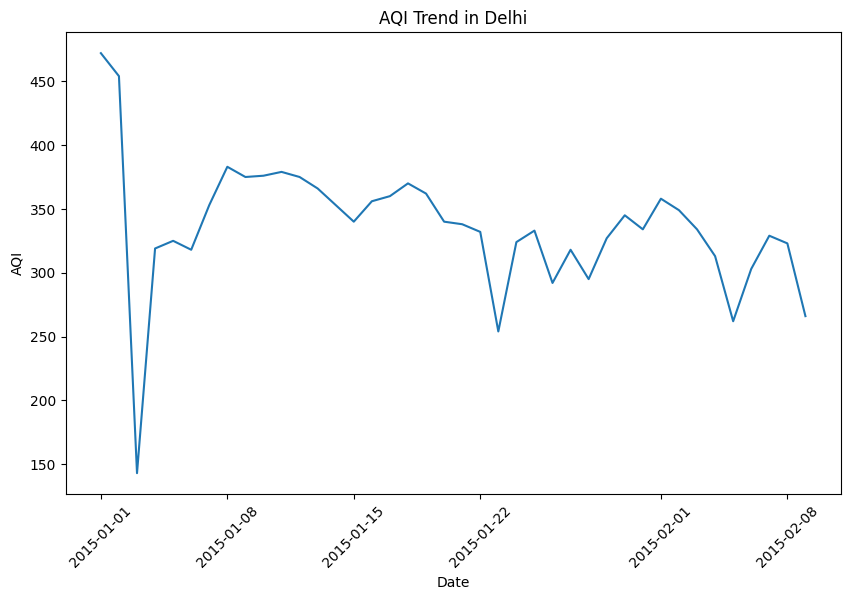

In [9]:

aqi_data = city_data.dropna(subset=['AQI']).head(40)

plt.figure(figsize=(10, 6))

plt.plot(aqi_data['Date'], aqi_data['AQI'])

plt.title('AQI Trend in Delhi')
plt.xlabel('Date')
plt.ylabel('AQI')
plt.xticks(rotation=45)

plt.show()


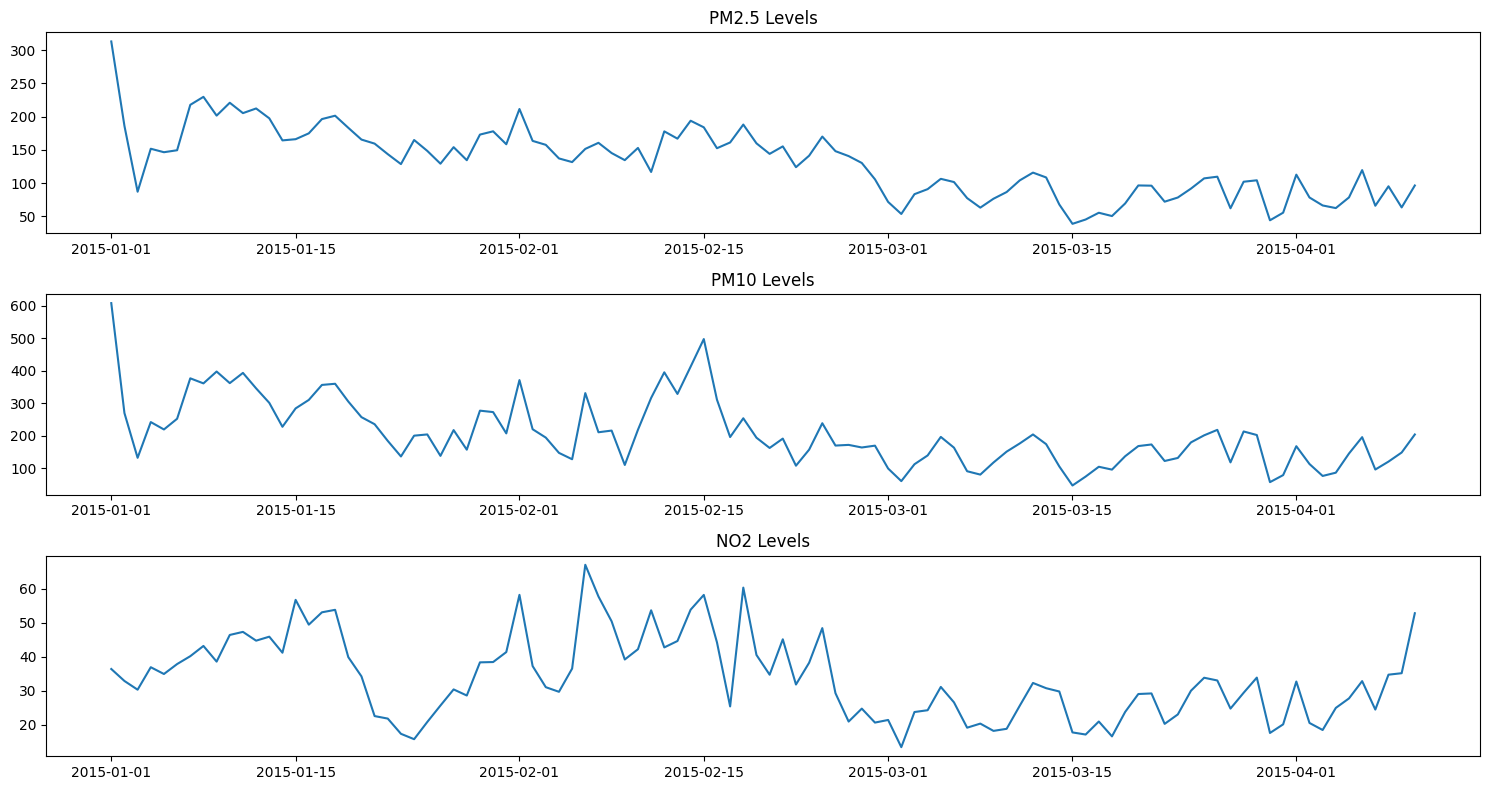

In [10]:

plot_data = city_data.dropna(
    subset=['PM2.5', 'PM10', 'NO2']
).head(100)

plt.figure(figsize=(15, 8))

plt.subplot(3, 1, 1)
plt.plot(plot_data['Date'], plot_data['PM2.5'])
plt.title('PM2.5 Levels')

plt.subplot(3, 1, 2)
plt.plot(plot_data['Date'], plot_data['PM10'])
plt.title('PM10 Levels')

plt.subplot(3, 1, 3)
plt.plot(plot_data['Date'], plot_data['NO2'])
plt.title('NO2 Levels')

plt.tight_layout()
plt.show()


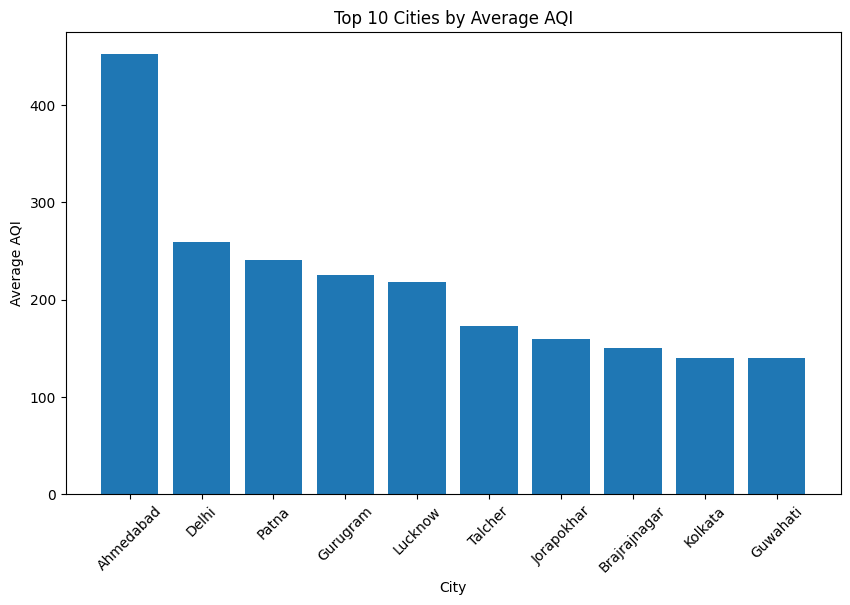

In [11]:

city_aqi = df.groupby('City')['AQI'].mean()

city_aqi = city_aqi.sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))

plt.bar(city_aqi.index, city_aqi.values)

plt.title('Top 10 Cities by Average AQI')
plt.xlabel('City')
plt.ylabel('Average AQI')
plt.xticks(rotation=45)

plt.show()


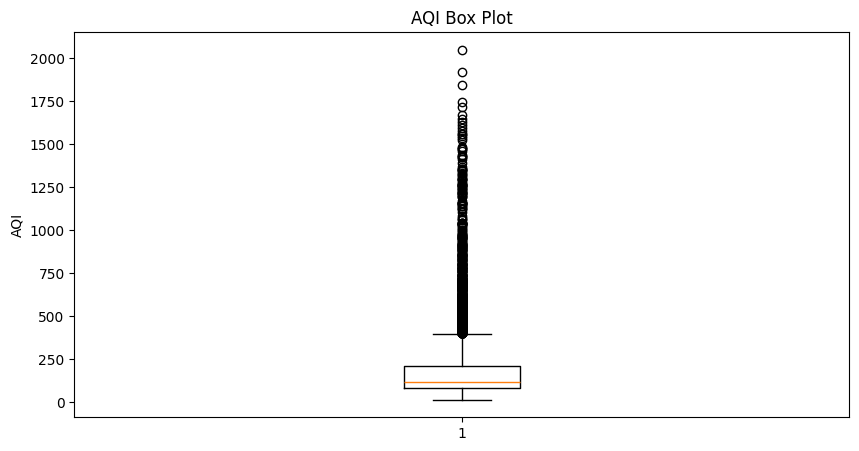

In [12]:

plt.figure(figsize=(10, 5))

plt.boxplot(df['AQI'].dropna())

plt.title('AQI Box Plot')
plt.ylabel('AQI')

plt.show()


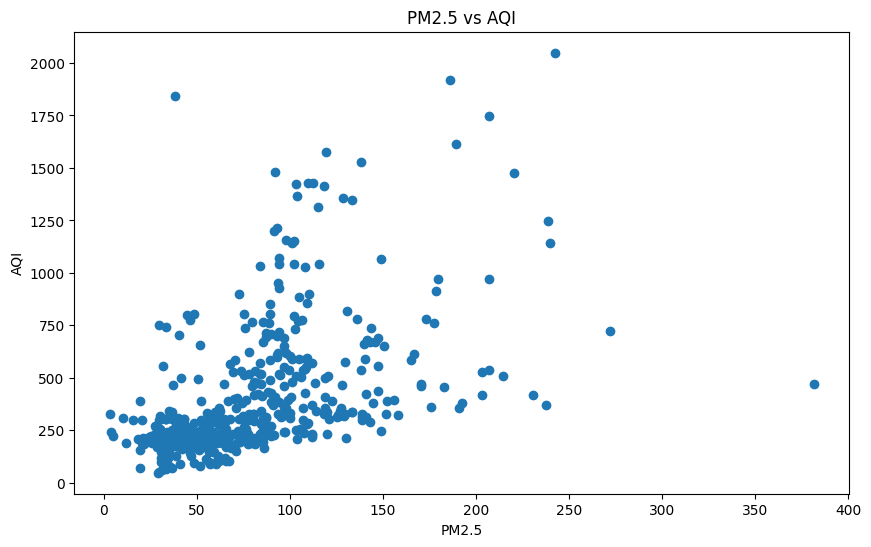

In [13]:

scatter_data = df.dropna(subset=['PM2.5', 'AQI']).head(500)

plt.figure(figsize=(10, 6))

plt.scatter(scatter_data['PM2.5'], scatter_data['AQI'])

plt.title('PM2.5 vs AQI')
plt.xlabel('PM2.5')
plt.ylabel('AQI')

plt.show()
